In [5]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import(
accuracy_score, 
classification_report, 
confusion_matrix,
precision_score,
recall_score,
f1_score,
roc_auc_score
)


In [6]:
df = pd.read_csv(r'C:\Users\HP\OneDrive\Desktop\KPMG sem3\Fraud_Detetction_rf_svm/fraud-detection.csv')

In [7]:
df.head()

,transaction_id,age,income,transaction_amount,account_age_days,transactions_24h,failed_attempts_24h,merchant_risk_score,distance_from_home_km,device_trust_score,is_international,is_new_device,transaction_hour,merchant_category,payment_method,is_fraud
0,1,23.0,30051.86,70.81,1400,5,2,0.1424,6.61,0.7174,0,0,1,gaming,card,0
1,2,62.0,40837.89,170.51,895,3,0,0.0680,7.05,0.8782,0,0,3,electronics,upi,0
2,3,55.0,63875.37,123.26,2136,6,0,0.2726,20.89,0.7289,0,0,11,electronics,net_banking,0
3,4,43.0,38929.69,408.65,58,4,0,0.0205,27.01,0.5039,0,0,1,grocery,upi,0
4,5,42.0,47192.34,420.26,2981,2,0,0.2680,2.13,0.7618,1,0,2,grocery,card,0


In [8]:
df.isnull().sum()

transaction_id             0
age                      351
income                   453
transaction_amount         0
account_age_days           0
transactions_24h           0
failed_attempts_24h        0
merchant_risk_score        0
distance_from_home_km      0
device_trust_score       198
is_international           0
is_new_device              0
transaction_hour           0
merchant_category        253
payment_method           199
is_fraud                   0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(197)

In [12]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9803 entries, 0 to 9999
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         9803 non-null   int64  
 1   age                    9458 non-null   float64
 2   income                 9359 non-null   float64
 3   transaction_amount     9803 non-null   float64
 4   account_age_days       9803 non-null   int64  
 5   transactions_24h       9803 non-null   int64  
 6   failed_attempts_24h    9803 non-null   int64  
 7   merchant_risk_score    9803 non-null   float64
 8   distance_from_home_km  9803 non-null   float64
 9   device_trust_score     9607 non-null   float64
 10  is_international       9803 non-null   int64  
 11  is_new_device          9803 non-null   int64  
 12  transaction_hour       9803 non-null   int64  
 13  merchant_category      9556 non-null   object 
 14  payment_method         9607 non-null   object 
 15  is_fraud 

In [19]:
x = df.drop(['is_fraud', 'transaction_id'], axis=1)
y = df['is_fraud']

print(x.shape)
print(y.shape)

x_train, x_test, y_train, y_test = train_test_split(
    x,y,test_size=0.2,random_state=42)




(9803, 14)
(9803,)


In [20]:
from sklearn.impute import SimpleImputer



numeric_cols = x.select_dtypes(include=['number']).columns.tolist()
categorical_cols = x.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)




Numeric columns: ['age', 'income', 'transaction_amount', 'account_age_days', 'transactions_24h', 'failed_attempts_24h', 'merchant_risk_score', 'distance_from_home_km', 'device_trust_score', 'is_international', 'is_new_device', 'transaction_hour']
Categorical columns: ['merchant_category', 'payment_method']


In [22]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

print("\nPreprocessing pipeline created.")


Preprocessing pipeline created.


In [24]:
# train the decisiion tree model using pipeline

fraud_detection_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth= 12, 
    min_samples_leaf=5, random_state=42))
]) 

model = fraud_detection_pipeline.fit(x_train, y_train)
y_pred = model.predict(x_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4 ))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC AUC Score:", round(roc_auc_score(y_test, y_pred), 4))

print("\nClassification Report:\n", classification_report(y_test, y_pred))




Accuracy: 0.8501
Precision: 0.3564
Recall: 0.2792
F1 Score: 0.3131
ROC AUC Score: 0.6044

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.93      0.92      1721
           1       0.36      0.28      0.31       240

    accuracy                           0.85      1961
   macro avg       0.63      0.60      0.61      1961
weighted avg       0.84      0.85      0.84      1961



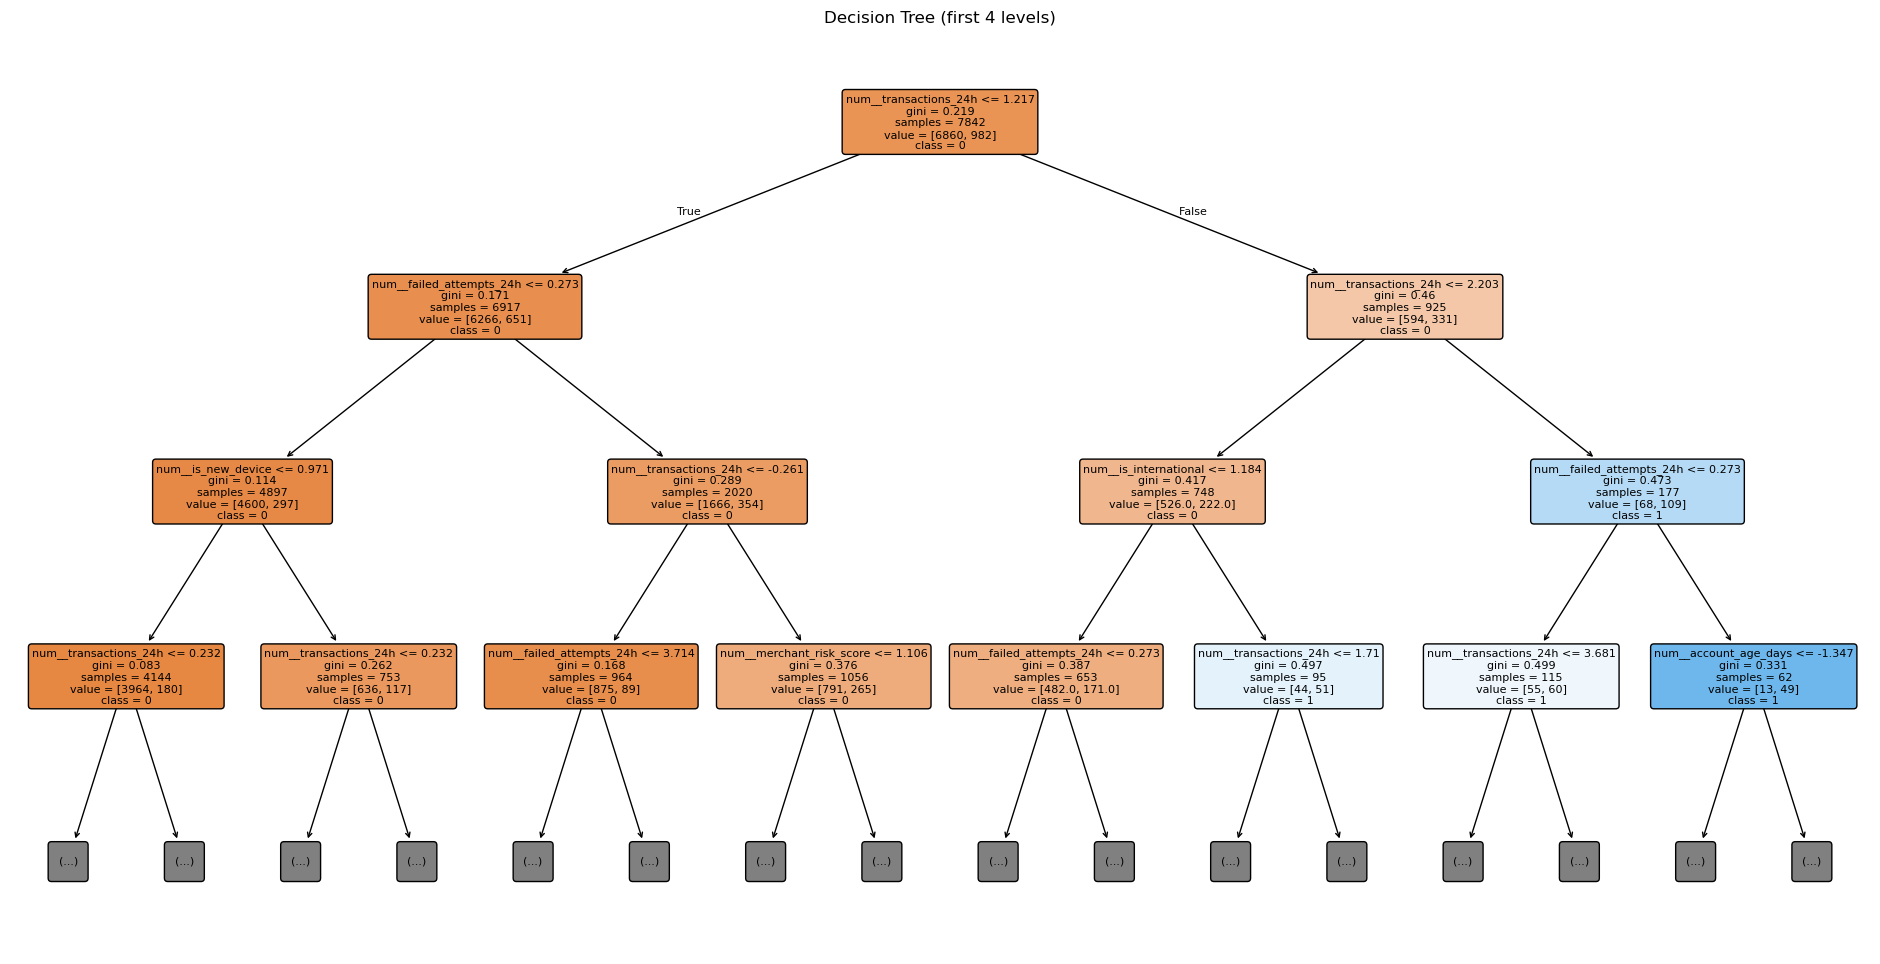

In [27]:
from sklearn.tree import plot_tree

import matplotlib.pyplot as plt

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
tree = model.named_steps["classifier"]

plt.figure(figsize=(24, 12))
plot_tree(
    tree,
    feature_names=feature_names,
    class_names=tree.classes_.astype(str),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree (first 4 levels)")
plt.show()

# RANDOM FOREST


In [40]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
         random_state=42, max_depth=15,min_samples_leaf=3,class_weight='balanced' ))


]) 

rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)

print("Random Forest Model Performance:")
print("Accuracy:", round(accuracy_score(y_test, y_pred_rf), 4))

print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall:", round(recall_score(y_test, y_pred_rf), 4 ))
print("F1 Score:", round(f1_score(y_test, y_pred_rf), 4
))
print("ROC AUC Score:", round(roc_auc_score(y_test, y_pred_rf),
    4))

print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))




Random Forest Model Performance:
Accuracy: 0.8858
Precision: 0.5667
Recall: 0.2833
F1 Score: 0.3778
ROC AUC Score: 0.6266

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.97      0.94      1721
           1       0.57      0.28      0.38       240

    accuracy                           0.89      1961
   macro avg       0.74      0.63      0.66      1961
weighted avg       0.86      0.89      0.87      1961



# SVM


In [33]:
# train the svm model using pipeline

svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', C=0.1, class_weight='balanced', 
    probability=True))
])

svm_model.fit(x_train, y_train)
svm_pred = svm_model.predict(x_test)

print("SVM Model Performance:")
print("Accuracy", round(accuracy_score(y_test, svm_pred),4))
print("\nClassification Report:\n", classification_report(y_test, svm_pred))

SVM Model Performance:
Accuracy 0.7292

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.73      0.83      1721
           1       0.27      0.74      0.40       240

    accuracy                           0.73      1961
   macro avg       0.61      0.73      0.61      1961
weighted avg       0.87      0.73      0.77      1961



In [36]:
# train the svm model using pipeline

svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='linear', C=0.1, class_weight='balanced', 
    probability=True))
])

svm_model.fit(x_train, y_train)
svm_pred = svm_model.predict(x_test)

print("SVM Model Performance:")
print("Accuracy", round(accuracy_score(y_test, svm_pred),4))
print("\nClassification Report:\n", classification_report(y_test, svm_pred))

SVM Model Performance:
Accuracy 0.7568

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.76      0.85      1721
           1       0.30      0.72      0.42       240

    accuracy                           0.76      1961
   macro avg       0.62      0.74      0.63      1961
weighted avg       0.87      0.76      0.79      1961



In [42]:
# train the svm model using pipeline

svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='poly', C=0.1, class_weight='balanced', 
))
])

svm_model.fit(x_train, y_train)
svm_pred = svm_model.predict(x_test)

print("SVM Model Performance:")
print("Accuracy", round(accuracy_score(y_test, svm_pred),4))
print("\nClassification Report:\n", classification_report(y_test, svm_pred))

SVM Model Performance:
Accuracy 0.8149

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.84      0.89      1721
           1       0.35      0.60      0.44       240

    accuracy                           0.81      1961
   macro avg       0.64      0.72      0.67      1961
weighted avg       0.87      0.81      0.83      1961



In [37]:
# train the svm model using pipeline

svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='sigmoid', C=0.1, class_weight='balanced', 
    probability=True))
])

svm_model.fit(x_train, y_train)
svm_pred = svm_model.predict(x_test)

print("SVM Model Performance:")
print("Accuracy", round(accuracy_score(y_test, svm_pred),4))
print("\nClassification Report:\n", classification_report(y_test, svm_pred))

SVM Model Performance:
Accuracy 0.7139

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.72      0.81      1721
           1       0.25      0.70      0.37       240

    accuracy                           0.71      1961
   macro avg       0.60      0.71      0.59      1961
weighted avg       0.86      0.71      0.76      1961

